# Task 1 - E-commerce Sales Analysis: Cleaning and EDA
Parts A and C. Run top to bottom from the `task1-ecommerce/` folder (or `notebooks/`).

In [1]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg") if "ipykernel" not in sys.modules else None
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from clean import load_raw, clean, export

CHARTS = ROOT / "charts"; CHARTS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold"})

def save(name):
    plt.tight_layout(); plt.savefig(CHARTS / f"{name}.png", dpi=150); plt.show()

## Part A - Load, inspect, clean

In [2]:
raw = load_raw()
for n, df in raw.items():
    print(f"\n=== {n}: shape={df.shape}")
    print(df.dtypes.to_string())
    print("null counts:", df.isna().sum()[df.isna().sum() > 0].to_dict() or "none")


=== customers: shape=(3000, 5)
customer_id      str
customer_name    str
city             str
state            str
signup_date      str
null counts: {'state': 60}

=== products: shape=(150, 4)
product_id          str
product_name        str
category            str
price           float64
null counts: none

=== orders: shape=(15120, 6)
order_id          str
customer_id       str
order_date        str
delivery_date     str
order_status      str
payment_method    str
null counts: {'delivery_date': 1365}

=== order_items: shape=(30058, 6)
order_item_id        str
order_id             str
product_id           str
quantity           int64
unit_price       float64
discount_pct     float64
null counts: {'discount_pct': 40}


In [3]:
# Issues found in the raw data
o = raw["orders"]
print("duplicate order rows :", o.duplicated().sum())
print("state values         :", sorted(raw["customers"].state.dropna().unique()))
print("order_date dtype     :", o.order_date.dtype, "(text, DD-MM-YYYY)")
print("missing discount_pct :", raw["order_items"].discount_pct.isna().sum())
print("missing delivery_date by status:\n", o[o.delivery_date.isna()].order_status.value_counts())

duplicate order rows : 120
state values         : ['DL', 'GJ', 'KA', 'MH', 'RJ', 'TN', 'UP', 'WB', 'dl', 'gj', 'ka', 'mh', 'rj', 'tn', 'up', 'wb']
order_date dtype     : str (text, DD-MM-YYYY)
missing discount_pct : 40
missing delivery_date by status:
 order_status
Cancelled    910
Shipped      455
Name: count, dtype: int64


### Cleaning decisions
| Issue | Decision | Why |
|---|---|---|
| 120 duplicate order rows | `drop_duplicates()` | They are exact copies; `order_id` is unique afterwards |
| State lower-case / missing | upper-case; fill nulls with the most common state of the customer's **city** | City maps reliably to a state, so no invented category is needed |
| Dates stored as text | `pd.to_datetime(..., format="%d-%m-%Y")` | Explicit format avoids day/month swaps |
| Missing `discount_pct` (40 rows) | Fill with **0** | Discount takes only {0,5,10,15,20}; 0 is mode and median (~43%). It never invents a discount. A `discount_imputed` flag keeps it auditable |
| Missing `delivery_date` | Keep as null | Expected for Cancelled/Shipped orders; imputing would corrupt delivery metrics |

In [4]:
data, log = clean(raw)
export(data)
customers, products, orders, items = data["customers"], data["products"], data["orders"], data["order_items"]
print({k: v.shape for k, v in data.items()})
orders[["order_id", "order_date", "delivery_date", "delivery_days", "order_status"]].head()

orders: removed 120 duplicate rows (15120 -> 15000)
customers.state: upper-cased; 60 nulls filled from city mode (0 left as UNKNOWN)
order_items.discount_pct: 40 nulls filled with 0 (mode & median)
orders.delivery_date missing only for {'Cancelled': 897, 'Shipped': 452} -> left null
{'customers': (3000, 5), 'products': (150, 4), 'orders': (15000, 8), 'order_items': (30058, 8)}


,order_id,order_date,delivery_date,delivery_days,order_status
0,O012225,2023-03-07,2023-03-09,2.0,Delivered
1,O000560,2024-11-24,2024-11-26,2.0,Delivered
2,O010736,2023-11-14,2023-11-24,10.0,Delivered
3,O013118,2023-08-16,2023-08-20,4.0,Delivered
4,O003671,2024-03-09,2024-03-20,11.0,Delivered


In [5]:
# One analysis table: item level + order + product + customer attributes
full = (items.merge(orders, on="order_id")
             .merge(products[["product_id", "category", "price"]], on="product_id")
             .merge(customers[["customer_id", "state", "city"]], on="customer_id"))
delivered = full[full.order_status == "Delivered"]          # revenue is counted on Delivered orders only
print("Delivered revenue: Rs {:,.0f}  |  orders: {:,}".format(delivered.revenue.sum(), delivered.order_id.nunique()))

Delivered revenue: Rs 312,104,994  |  orders: 12,906


## Part C - EDA and visualisation

### Chart 1 - Monthly revenue trend

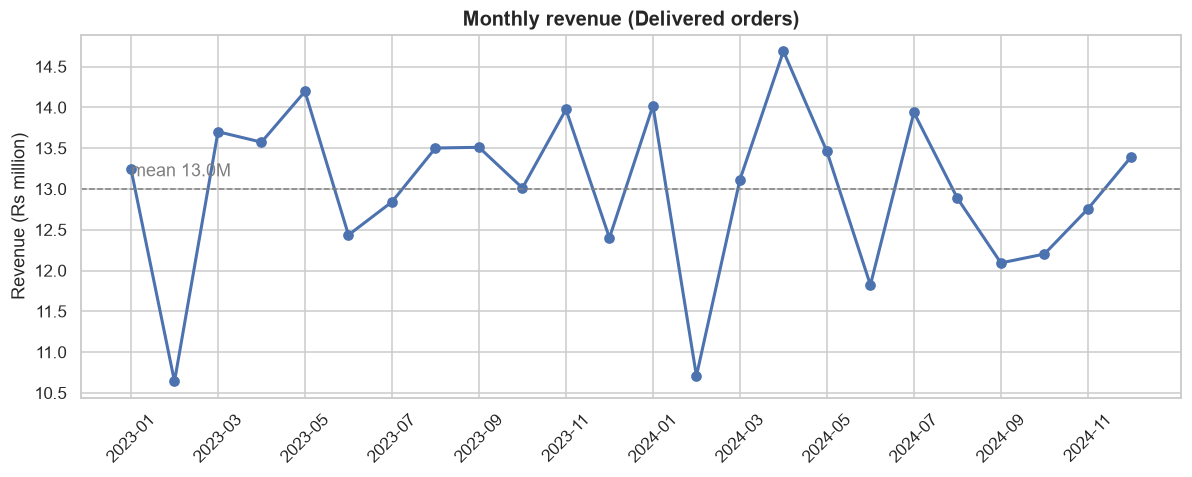

order_date
2023    157026679.0
2024    155078316.0
Name: revenue, dtype: float64


In [6]:
m = delivered.groupby("order_month").revenue.sum() / 1e6
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(m.index, m.values, marker="o", lw=2)
ax.set_title("Monthly revenue (Delivered orders)"); ax.set_ylabel("Revenue (Rs million)")
ax.set_xticks(range(0, len(m), 2)); ax.set_xticklabels(m.index[::2], rotation=45)
ax.axhline(m.mean(), ls="--", c="grey", lw=1); ax.text(0, m.mean() + .15, f"mean {m.mean():.1f}M", color="grey")
save("01_revenue_trend")
print(delivered.groupby(delivered.order_date.dt.year).revenue.sum().round(0))

**Insight:** Revenue is flat at roughly Rs 26M a month with no real growth (2023 Rs 157.0M vs 2024 Rs 155.1M, about -1.2%). February is the weakest month, partly because it is shorter. The business is not growing, so growth has to come from mix and retention rather than seasonality.

### Chart 2 - Category share of revenue

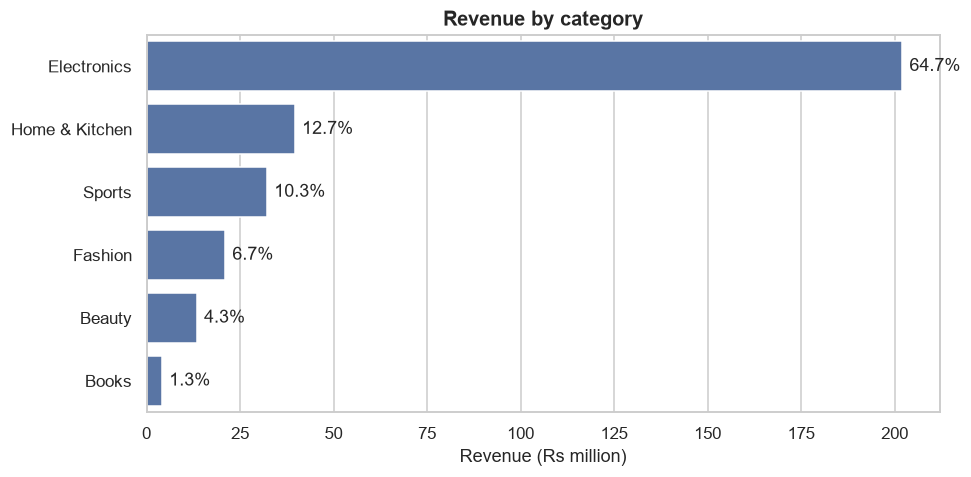

In [7]:
cat = delivered.groupby("category").revenue.sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=cat.values / 1e6, y=cat.index, ax=ax)
for k, v in enumerate(cat.values / cat.sum() * 100):
    ax.text(cat.values[k] / 1e6 + 2, k, f"{v:.1f}%", va="center")
ax.set_title("Revenue by category"); ax.set_xlabel("Revenue (Rs million)"); ax.set_ylabel("")
save("02_category_share")

**Insight:** Electronics generates 64.7% of revenue; Books is only 1.3%. Revenue is highly concentrated in one category, so Electronics availability, pricing and returns drive the whole P&L.

### Chart 3 - Order status split

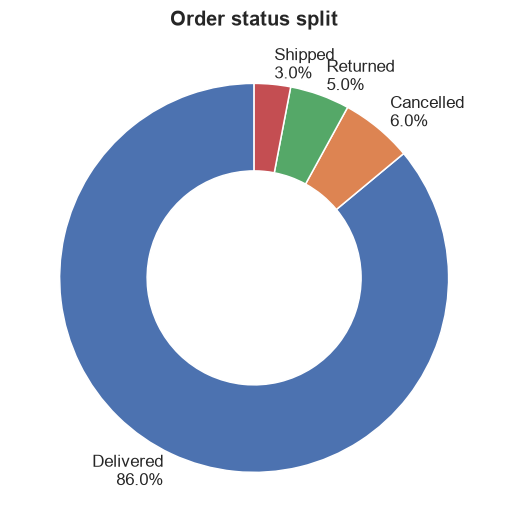

In [8]:
st = orders.order_status.value_counts()
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.pie(st.values, labels=[f"{k}\n{v / st.sum() * 100:.1f}%" for k, v in st.items()],
       startangle=90, wedgeprops=dict(width=.45, edgecolor="white"))
ax.set_title("Order status split")
save("03_order_status")

**Insight:** 86% of orders are delivered, but 6% are cancelled and 5% returned, so about 11% of orders never produce revenue. Cutting cancellations and returns by even a third would be a cheap revenue gain.

### Chart 4 - Delivery-days distribution

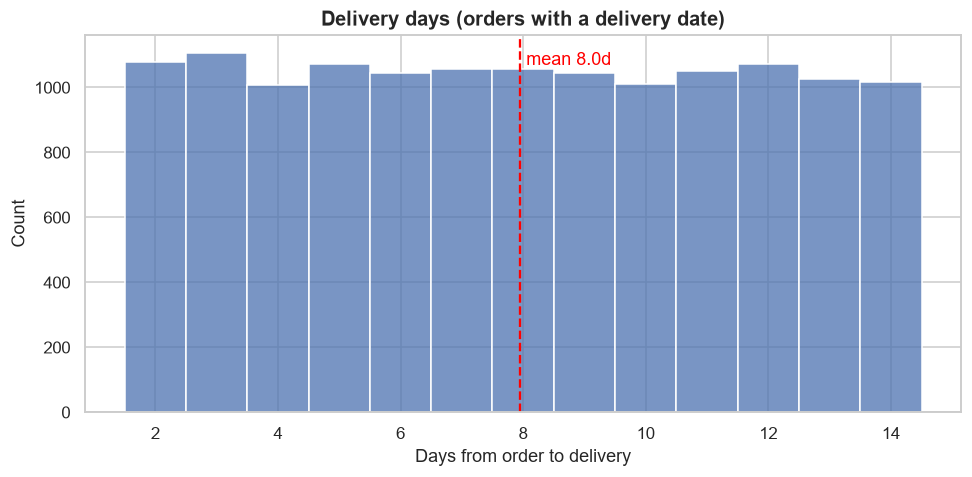

count    13651.00
mean         7.95
std          3.75
min          2.00
25%          5.00
50%          8.00
75%         11.00
max         14.00
Name: delivery_days, dtype: float64


In [9]:
dd = orders.delivery_days.dropna()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(dd, bins=range(2, 16), discrete=True, ax=ax)
ax.axvline(dd.mean(), c="red", ls="--"); ax.text(dd.mean() + .1, ax.get_ylim()[1] * .92, f"mean {dd.mean():.1f}d", color="red")
ax.set_title("Delivery days (orders with a delivery date)"); ax.set_xlabel("Days from order to delivery")
save("04_delivery_days")
print(dd.describe().round(2))

**Insight:** Delivery takes 2 to 14 days with a mean of 8 and an almost flat spread, so there is no "normal" speed. A quarter of orders take 11 days or more, which is slow for e-commerce. Delivery is inconsistent, not just slow.

### Chart 5 - State-wise revenue

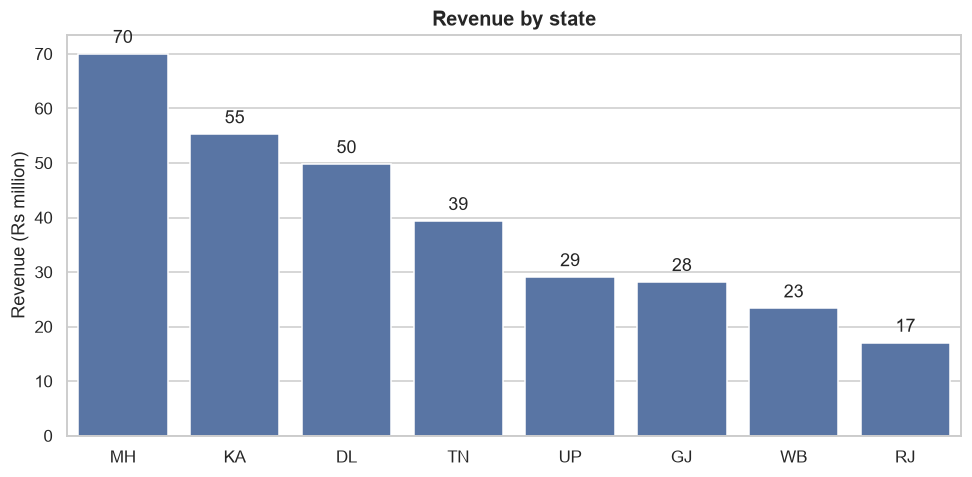

{'MH': 22.4, 'KA': 17.7, 'DL': 16.0, 'TN': 12.6, 'UP': 9.3, 'GJ': 9.0, 'WB': 7.5, 'RJ': 5.5}


In [10]:
stt = delivered.groupby("state").revenue.sum().sort_values(ascending=False) / 1e6
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=stt.index, y=stt.values, ax=ax)
for k, v in enumerate(stt.values): ax.text(k, v + 2, f"{v:.0f}", ha="center")
ax.set_title("Revenue by state"); ax.set_ylabel("Revenue (Rs million)"); ax.set_xlabel("")
save("05_state_revenue")
print((stt / stt.sum() * 100).round(1).to_dict())

**Insight:** Maharashtra, Karnataka and Delhi contribute 56% of revenue (22.4%, 17.7%, 16.0%). Rajasthan (5.5%) and West Bengal (7.5%) are under-penetrated and are the natural targets for marketing spend.

### Chart 6 - Discount vs quantity

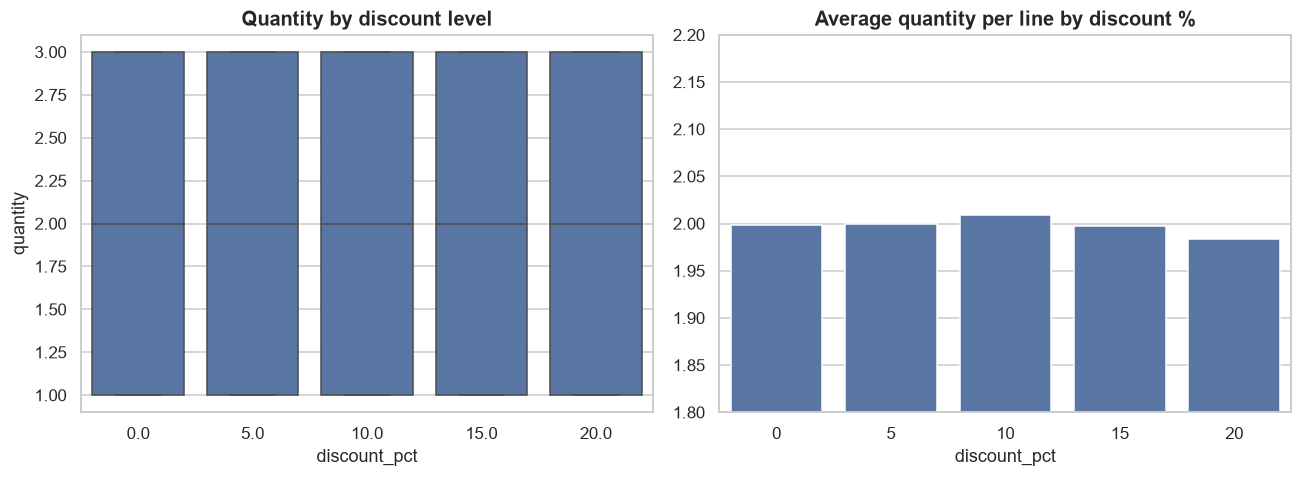

corr(discount, quantity) = -0.0042
{0.0: 1.999, 5.0: 2.0, 10.0: 2.009, 15.0: 1.997, 20.0: 1.983}


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=full, x="discount_pct", y="quantity", ax=axes[0]); axes[0].set_title("Quantity by discount level")
avgq = full.groupby("discount_pct").quantity.mean()
sns.barplot(x=avgq.index.astype(int), y=avgq.values, ax=axes[1]); axes[1].set_ylim(1.8, 2.2)
axes[1].set_title("Average quantity per line by discount %"); axes[1].set_xlabel("discount_pct")
save("06_discount_vs_quantity")
print("corr(discount, quantity) =", round(full[["discount_pct", "quantity"]].corr().iloc[0, 1], 4))
print(full.groupby("discount_pct").quantity.mean().round(3).to_dict())

**Insight:** Discounts do not change how much people buy (correlation about 0.00; average quantity about 2.0 at every discount level), so discounts give away margin without lifting volume. Test cutting the 15 to 20% discounts.

### Chart 7 - Order value outliers (IQR method)

Q1=4,897 Q3=28,449 IQR=23,552 -> fences [-30,432, 63,778]
outliers: 1,531 orders (11.9%), carrying 47.3% of revenue
mean order value 24,183 vs median 12,052


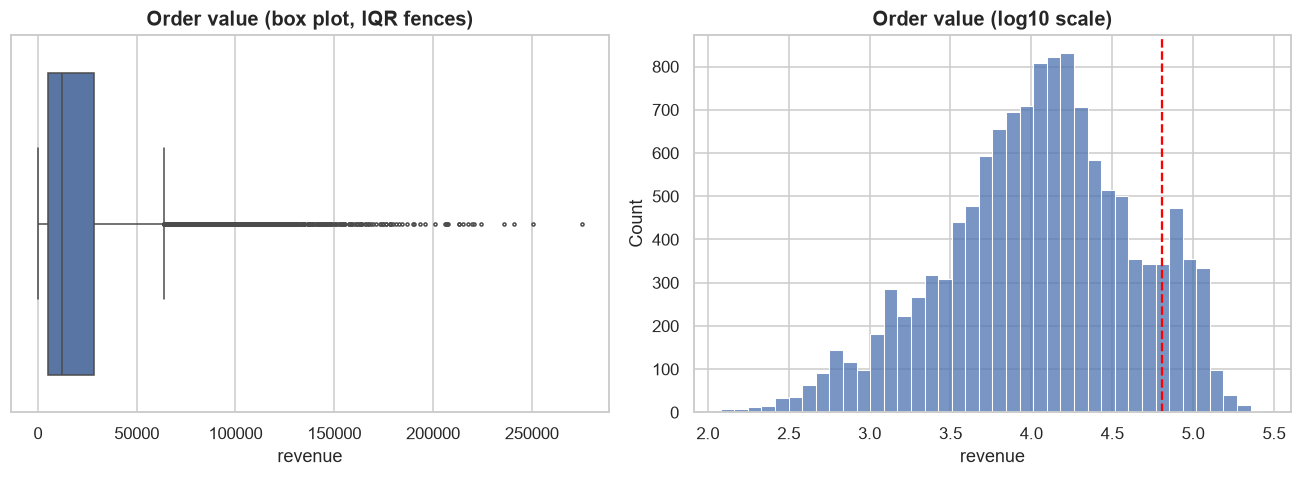

In [12]:
ov = delivered.groupby("order_id").revenue.sum()
q1, q3 = ov.quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = ov[(ov < lo) | (ov > hi)]
print(f"Q1={q1:,.0f} Q3={q3:,.0f} IQR={iqr:,.0f} -> fences [{lo:,.0f}, {hi:,.0f}]")
print(f"outliers: {len(out):,} orders ({len(out) / len(ov):.1%}), carrying {out.sum() / ov.sum():.1%} of revenue")
print(f"mean order value {ov.mean():,.0f} vs median {ov.median():,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x=ov, ax=axes[0], showfliers=True, fliersize=2); axes[0].set_title("Order value (box plot, IQR fences)")
sns.histplot(np.log10(ov), bins=40, ax=axes[1]); axes[1].set_title("Order value (log10 scale)")
axes[1].axvline(np.log10(hi), c="red", ls="--")
save("07_order_value_outliers")

**How outliers were handled:** 1,531 orders (11.9%) sit above the upper fence of about Rs 63.8k and carry 47% of revenue. They are **not errors**: they are multi-item Electronics orders at real catalogue prices, so deleting them would delete genuine revenue. They are kept in all totals. For skew-sensitive statements, the **median order value (Rs 12.1k)** is reported next to the mean (Rs 24.2k), and the dashboard shows both.

**Insight:** The heavy right tail means averages overstate a typical order. Roughly 12% of orders generate almost half of revenue, so protecting and retaining those high-value baskets matters most.

In [13]:
print("Charts written to", CHARTS)

Charts written to C:\Users\User\Downloads\ds-assignments\task1-ecommerce\charts
